In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Cargar desde URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = ['Embarazos', 'Glucosa', 'Presion', 'Piel', 'Insulina', 'IMC', 'Pedigree', 'Edad', 'Clase']
diabetes = pd.read_csv(url, names=columnas)

# Verificamos la carga
print(f"Dimensiones: {diabetes.shape}")
diabetes.head()

Dimensiones: (768, 9)


,Embarazos,Glucosa,Presion,Piel,Insulina,IMC,Pedigree,Edad,Clase
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


C:\Users\magal\AppData\Local\Temp\ipykernel_12100\4121379069.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Clase', y='Glucosa', data=diabetes, palette={'0':'skyblue', '1':'salmon'})


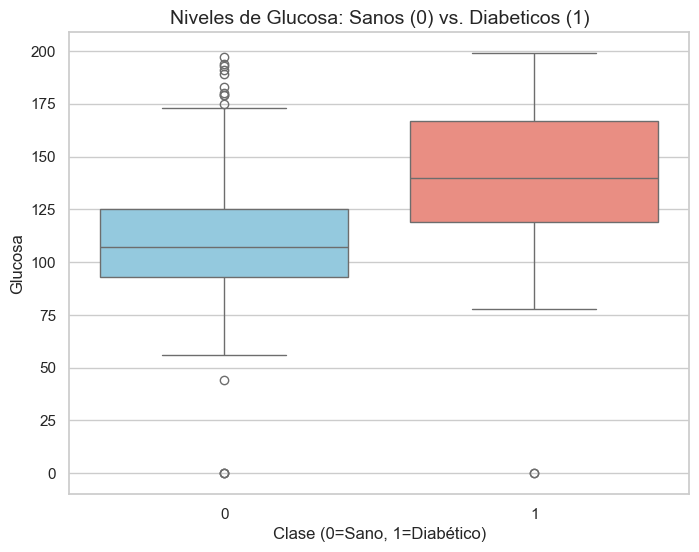

In [2]:
# Configuración estética
sns.set(style="whitegrid")

# Gráfico de Caja: Glucosa vs. Diabetes
plt.figure(figsize=(8, 6))
sns.boxplot(x='Clase', y='Glucosa', data=diabetes, palette={'0':'skyblue', '1':'salmon'})
plt.title('Niveles de Glucosa: Sanos (0) vs. Diabeticos (1)', fontsize=14)
plt.xlabel('Clase (0=Sano, 1=Diabético)')
plt.ylabel('Glucosa')
plt.show()

In [3]:
from sklearn.model_selection import train_test_split

# 1. Separar X (Variables) e y (Objetivo)
X = diabetes.drop('Clase', axis=1)
y = diabetes['Clase']

# 2. Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {X_train.shape[0]} pacientes")
print(f"Prueba: {X_test.shape[0]} pacientes")

Entrenamiento: 614 pacientes
Prueba: 154 pacientes


In [21]:
from sklearn.ensemble import RandomForestClassifier

# Instanciar el Bosque
# n_estimators=100: Creamos 100 árboles
# random_state=42: Para resultados reproducibles
rf_model = RandomForestClassifier(n_estimators=120, random_state=42)

# Entrenar
rf_model.fit(X_train, y_train)

print("¡Modelo Random Forest entrenado exitosamente!")

¡Modelo Random Forest entrenado exitosamente!


ACCURACY (Exactitud): 73.38%

--- Matriz de Confusión ---


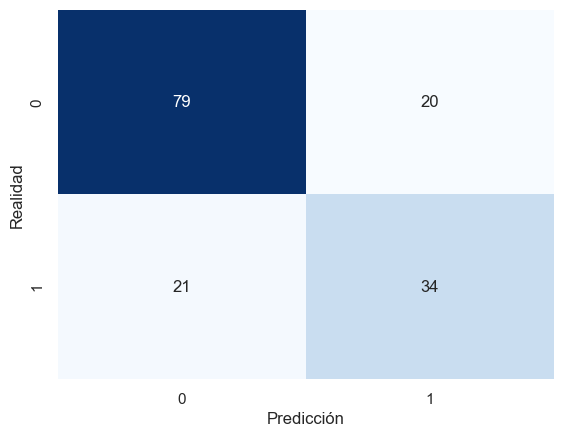


--- Reporte de Clasificación ---
              precision    recall  f1-score   support

           0       0.79      0.80      0.79        99
           1       0.63      0.62      0.62        55

    accuracy                           0.73       154
   macro avg       0.71      0.71      0.71       154
weighted avg       0.73      0.73      0.73       154



In [22]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Predecir
y_pred = rf_model.predict(X_test)

# Calcular métricas
acc = accuracy_score(y_test, y_pred)
print(f"ACCURACY (Exactitud): {acc:.2%}\n")

print("--- Matriz de Confusión ---")
# Visualizar la matriz
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

print("\n--- Reporte de Clasificación ---")
print(classification_report(y_test, y_pred))

C:\Users\magal\AppData\Local\Temp\ipykernel_12100\2118207287.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Peso', y='Variable', data=importancia, palette='viridis')


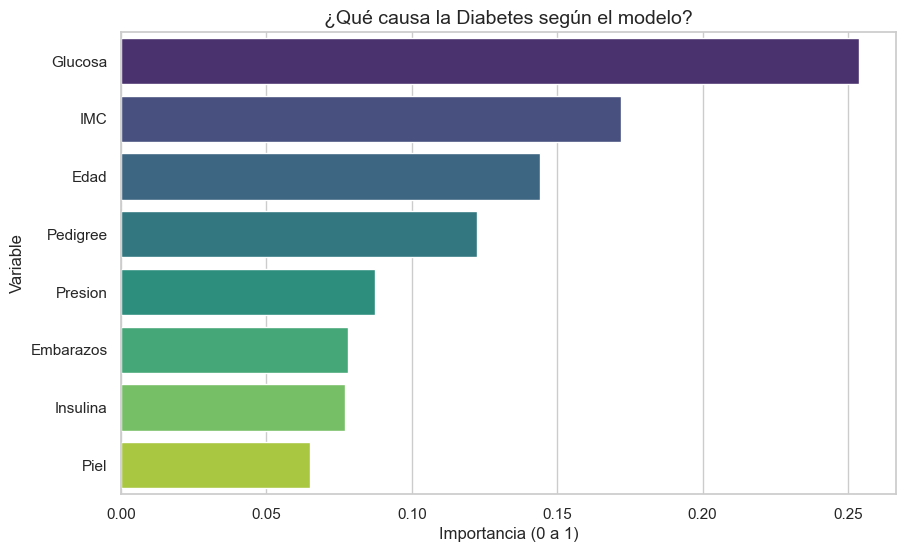

    Variable      Peso
1    Glucosa  0.253846
5        IMC  0.171916
7       Edad  0.144261
6   Pedigree  0.122578
2    Presion  0.087408
0  Embarazos  0.077933
4   Insulina  0.077137
3       Piel  0.064923


In [23]:
# Extraer la importancia de cada variable
importancia = pd.DataFrame({
    'Variable': X.columns,
    'Peso': rf_model.feature_importances_
}).sort_values(by='Peso', ascending=False)

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x='Peso', y='Variable', data=importancia, palette='viridis')
plt.title('¿Qué causa la Diabetes según el modelo?', fontsize=14)
plt.xlabel('Importancia (0 a 1)')
plt.show()

# Mostrar tabla numérica
print(importancia)

Precisión Regresión Logística: 74.68%


C:\Users\magal\AppData\Local\Temp\ipykernel_12100\550973411.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Peso', y='Variable', data=importancia_log, palette='magma')


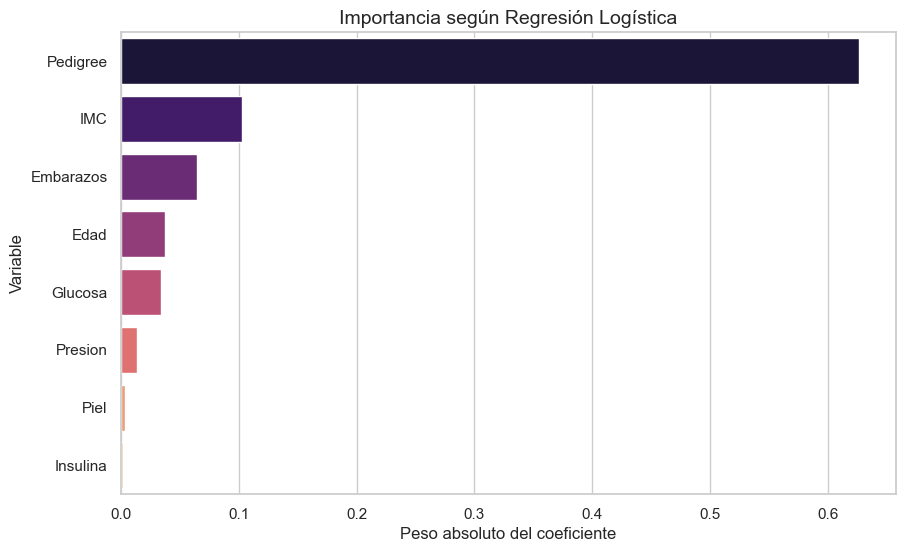

,Variable,Peso
6,Pedigree,0.626741
5,IMC,0.102607
0,Embarazos,0.064376
7,Edad,0.037096
1,Glucosa,0.034095
2,Presion,0.013879
3,Piel,0.003292
4,Insulina,0.001804


In [24]:
from sklearn.linear_model import LogisticRegression

# Entrenar Logística (Modelo Base)
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)

# Mostrar precisión (accuracy)
acc_log = accuracy_score(y_test, y_pred_log)
print(f"Precisión Regresión Logística: {acc_log:.2%}")

# Importancia de variables según Regresión Logística
importancia_log = pd.DataFrame({
    'Variable': X.columns,
    'Peso': np.abs(log_model.coef_[0])
}).sort_values(by='Peso', ascending=False)

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x='Peso', y='Variable', data=importancia_log, palette='magma')
plt.title('Importancia según Regresión Logística', fontsize=14)
plt.xlabel('Peso absoluto del coeficiente')
plt.show()

# Mostrar tabla numérica
display(importancia_log)

In [30]:
from sklearn.ensemble import AdaBoostClassifier

# 1. Instanciar y Entrenar AdaBoost
# n_estimators=50: Suele ser suficiente para empezar en boosting
ada_model = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_model.fit(X_train, y_train)

# 2. Predecir
y_pred_ada = ada_model.predict(X_test)

# 3. Evaluar
acc_ada = accuracy_score(y_test, y_pred_ada)
print(f"AdaBoost Accuracy: {acc_ada:.2%}")

print("\n--- Reporte AdaBoost ---")
print(classification_report(y_test, y_pred_ada))

AdaBoost Accuracy: 77.92%

--- Reporte AdaBoost ---
              precision    recall  f1-score   support

           0       0.84      0.81      0.82        99
           1       0.68      0.73      0.70        55

    accuracy                           0.78       154
   macro avg       0.76      0.77      0.76       154
weighted avg       0.78      0.78      0.78       154



C:\Users\magal\AppData\Local\Temp\ipykernel_12100\958221309.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Peso', y='Variable', data=importancia_ada, palette='plasma')


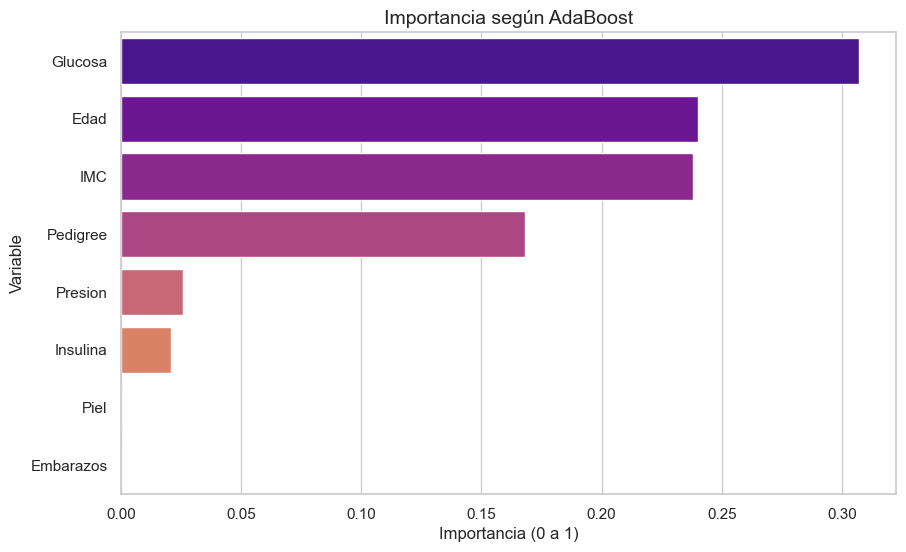

,Variable,Peso
1,Glucosa,0.307137
7,Edad,0.239930
5,IMC,0.238076
6,Pedigree,0.168234
2,Presion,0.025736
4,Insulina,0.020887
3,Piel,0.000000
0,Embarazos,0.000000


In [26]:
# Importancia de variables según AdaBoost
importancia_ada = pd.DataFrame({
    'Variable': X.columns,
    'Peso': ada_model.feature_importances_
}).sort_values(by='Peso', ascending=False)

# Graficar
plt.figure(figsize=(10, 6))
sns.barplot(x='Peso', y='Variable', data=importancia_ada, palette='plasma')
plt.title('Importancia según AdaBoost', fontsize=14)
plt.xlabel('Importancia (0 a 1)')
plt.show()

# Mostrar tabla numérica
display(importancia_ada)

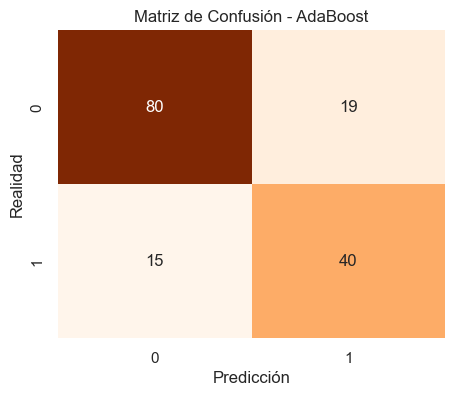

In [27]:
# Matriz de confusión para AdaBoost
cm_ada = confusion_matrix(y_test, y_pred_ada)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_ada, annot=True, fmt='d', cmap='Oranges', cbar=False)
plt.title('Matriz de Confusión - AdaBoost')
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.show()

In [28]:
# Resumen de precisión de los 3 modelos
print("\n--- Resumen de Precisión de Modelos ---")
print(f"Regresión Logística: {acc_log:.2%}")
print(f"Random Forest:       {acc:.2%}")
print(f"AdaBoost:            {acc_ada:.2%}")


--- Resumen de Precisión de Modelos ---
Regresión Logística: 74.68%
Random Forest:       73.38%
AdaBoost:            77.92%
